# Sampling with gradients: NUTS against emcee and dynesty

The densities of a compiled problem are written in JAX, so their exact
gradient is available, through the models, the covariance and the reaction
solver.  A gradient sampler, the No-U-Turn sampler ([NUTS](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#nuts)) of
[Hamiltonian Monte Carlo](https://en.wikipedia.org/wiki/Hamiltonian_Monte_Carlo),
uses it to take long, directed steps instead of a random walk.  Whether that
pays depends on the problem: a NUTS draw costs tens of gradient evaluations,
while an [emcee](https://emcee.readthedocs.io/en/stable/) step costs one
density evaluation per walker.

We compare NUTS with emcee and with the nested sampler
[dynesty](https://dynesty.readthedocs.io/en/stable/overview.html) on three
problems, by *effective* samples per second, the number that decides how
long a calibration takes:

1. a hierarchy with 33 parameters, where NUTS should win;
2. a 5-parameter Gaussian-process discrepancy, where it should not;
3. the p + ⁴⁰Ca optical model of `local_optical_model_calibration`.

On the way we use the gradient twice more: a
[MAP](https://en.wikipedia.org/wiki/Maximum_a_posteriori_estimation) estimate
by a quasi-Newton search, and a
[Laplace approximation](https://en.wikipedia.org/wiki/Laplace%27s_approximation)
from the exact Hessian.

Recipes: 16, 33, 41

In [1]:
import logging
import time

import blackjax
import corner
import dynesty
import emcee
import jax
import jax.numpy as jnp
import jitr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotstyle
import tinygp
from jitr.optical_potentials.potential_forms import (
    coulomb_charged_sphere,
    thomas_safe,
    woods_saxon_prime_safe,
    woods_saxon_safe,
)
from scipy import stats
from scipy.optimize import minimize

import rxmc as rx
from rxmc import terms as T
from rxmc import transforms as tf

plotstyle.use()
logging.getLogger("emcee").setLevel(logging.ERROR)  # score() reports tau itself

## The three samplers, and how we compare them

rxmc owns no sampler; each of these is a few lines on the problem's
densities.

- **emcee** moves an ensemble of walkers, each by a
  [stretch move](https://emcee.readthedocs.io/en/stable/user/moves/) along
  the line to another walker: no gradient and no tuning, one density
  evaluation per walker per step.
- **dynesty** does
  [nested sampling](https://en.wikipedia.org/wiki/Nested_sampling_algorithm):
  it shrinks a set of live points through nested contours of the likelihood
  under the prior, and computes the evidence on the way.
- **NUTS** ([NUTS](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#nuts)) follows Hamiltonian trajectories with the
  gradient and stops each one when it starts to turn back; its step size and
  mass matrix are tuned in a discarded
  [warm-up](https://blackjax-devs.github.io/blackjax/examples/quickstart.html#use-stan-s-window-adaptation).

NUTS runs on `log_posterior_unconstrained`, the posterior on
$\mathbb{R}^n$: a bounded parameter is sampled as a log or a logit, so a
trajectory never meets the $-\infty$ wall at a bound, and `to_theta` maps
the draws back (recipe 41).  Its chains run one after another; vmapped,
every chain would wait at each step for the longest trajectory.

The comparison:

- The [effective sample size](https://mc-stan.org/docs/reference-manual/analysis.html)
  (ESS) of a correlated chain is the number of independent draws that would
  estimate a posterior mean as precisely.  We take the smallest over the
  parameters, from blackjax's
  [estimator](https://blackjax-devs.github.io/blackjax/autoapi/blackjax/diagnostics/index.html)
  across chains, and divide it by the wall time, compilation included.
- The split [$\hat R$](https://en.wikipedia.org/wiki/Gelman-Rubin_statistic)
  ([Vehtari et al. 2021](https://arxiv.org/abs/1903.08008)) compares the
  spread within each chain with the spread between them.  Above about 1.01
  the chains have not yet forgotten where they started, their ESS means
  nothing, and we report the run as not converged.
- emcee's walkers are taken as chains, which flatters its ESS: they are not
  independent, since each move uses another walker.  So we also print
  emcee's own
  [integrated autocorrelation time](https://emcee.readthedocs.io/en/stable/tutorials/autocorr/)
  $\tau$, the number of steps over which a walker remembers its past; emcee
  trusts a run only when it is longer than about $50\tau$.
- dynesty's draws are weighted, not correlated, so its ESS is
  [Kish's](https://en.wikipedia.org/wiki/Effective_sample_size), from the
  importance weights, and it has no $\hat R$.

In [2]:
def run_nuts(problem, starts, warmup=1000, draws=1000, seed=0):
    """One window-adapted NUTS chain per row of ``starts``; draws in theta."""
    logdensity = problem.log_posterior_unconstrained
    t0, chains, divergent, n_grad = time.perf_counter(), [], 0, 0
    for i, theta0 in enumerate(starts):
        k_warm, k_draw = jax.random.split(jax.random.key(seed + i))
        adapt = blackjax.window_adaptation(blackjax.nuts, logdensity)
        (state, tuned), warm = adapt.run(
            k_warm, problem.to_unconstrained(theta0), num_steps=warmup
        )
        step = jax.jit(blackjax.nuts(logdensity, **tuned).step)

        def one_step(state, key):
            state, info = step(key, state)
            return state, (state.position, info)

        _, (zs, info) = jax.lax.scan(one_step, state, jax.random.split(k_draw, draws))
        chains.append(np.asarray(jax.vmap(problem.to_theta)(zs)))
        divergent += int(info.is_divergent.sum())
        n_grad += int(
            warm.info.num_integration_steps.sum() + info.num_integration_steps.sum()
        )
    return np.stack(chains), dict(
        wall=time.perf_counter() - t0, evaluations=n_grad, divergences=divergent
    )


def run_emcee(problem, steps, seed=0):
    """emcee from the prior, the first third discarded; walkers as chains."""
    n_walkers = max(32, 2 * problem.ndim + 2)
    t0 = time.perf_counter()
    sampler = emcee.EnsembleSampler(
        n_walkers, problem.ndim, problem.log_posterior_batch, vectorize=True
    )
    sampler.random_state = np.random.RandomState(seed).get_state()
    sampler.run_mcmc(problem.sample_prior(n_walkers, rng=seed), steps, progress=False)
    kept = sampler.get_chain(discard=steps // 3)
    tau = float(np.max(sampler.get_autocorr_time(discard=steps // 3, quiet=True)))
    return np.swapaxes(kept, 0, 1), dict(
        wall=time.perf_counter() - t0,
        evaluations=n_walkers * steps,
        tau=tau,
        steps_kept=len(kept),
    )


def run_dynesty(problem, nlive=100, seed=0):
    """Nested sampling from the prior; equal-weight draws and Kish's ESS."""
    t0 = time.perf_counter()
    sampler = dynesty.NestedSampler(
        problem.log_likelihood,
        problem.prior_transform,
        problem.ndim,
        nlive=nlive,
        sample="rwalk",
        rstate=np.random.default_rng(seed),
    )
    sampler.run_nested(dlogz=0.5, print_progress=False)
    res = sampler.results
    w = np.exp(res.logwt - res.logz[-1])
    samples = res.samples_equal(rstate=np.random.default_rng(seed))
    return samples[None], dict(
        wall=time.perf_counter() - t0,
        evaluations=int(np.sum(res.ncall)),
        ess=float(w.sum() ** 2 / np.sum(w**2)),
    )


def overlay(runs, colours, labels, title):
    """Corner plots of several runs on shared axes, each histogram normalised."""
    ranges = [np.percentile(runs[-1][:, k], [0.2, 99.8]) for k in range(len(labels))]
    ranges = [(lo - 0.3 * (hi - lo), hi + 0.3 * (hi - lo)) for lo, hi in ranges]
    fig = None
    for run, colour in zip(runs, colours):
        fig = corner.corner(
            run,
            fig=fig,
            labels=labels,
            range=ranges,
            hist_kwargs={"density": True},
            **plotstyle.corner_kwargs(show_titles=False, color=colour),
        )
    fig.suptitle(title)
    plt.show()


def score(name, chains, info):
    """Print a sampler's line of the comparison; ESS only for a converged run."""
    line = f"{name:8s} {info['wall']:7.1f} s  {info['evaluations']:7d} evaluations  "
    if "ess" in info:  # dynesty
        line += f"ESS {info['ess']:5.0f}  ESS/s {info['ess'] / info['wall']:6.2f}"
    else:
        ess = float(np.min(blackjax.diagnostics.effective_sample_size(chains)))
        rhat = float(np.max(blackjax.diagnostics.potential_scale_reduction(chains)))
        if rhat <= 1.01:
            line += f"ESS {ess:5.0f}  ESS/s {ess / info['wall']:6.2f}  R-hat {rhat:.3f}"
        else:
            line += f"not converged, R-hat {rhat:.3f}"
    if "tau" in info:
        enough = info["steps_kept"] > 50 * info["tau"]
        line += f"  tau {info['tau']:.0f} steps" + ("" if enough else " (< 50 tau)")
    if "divergences" in info:
        line += f"  {info['divergences']} divergent"
    print(line)

## 1. A hierarchy: where gradients pay

Thirty groups each measure a line.  They share the slope $m$, and their
intercepts scatter about a common $\mu$ with an unknown spread $\tau$,
written non-centred as $\mu + \tau\,\eta_j$ with
$\eta_j \sim \mathcal{N}(0, 1)$ (recipe 38): 33 parameters, most of them the
$\eta_j$.  (This $\tau$ is the hierarchy's spread, not emcee's
autocorrelation time.)  A stretch move proposes along the line between two
walkers, and in 33 dimensions few such lines point anywhere useful.

In [3]:
rng = np.random.default_rng(5)
x = np.linspace(0.0, 1.0, 5)
m = rx.Parameter("m", prior=stats.norm(0, 5), latex="m")
mu = rx.Parameter("mu", prior=stats.norm(0, 5), latex=r"\mu")
tau = rx.Parameter(
    "tau", prior=stats.halfnorm(scale=1.0), bounds=(0.0, np.inf), latex=r"\tau"
)
comps = []
for j in range(30):
    eta = rx.Parameter(f"eta_{j}", prior=stats.norm(0, 1), latex=rf"\eta_{{{j}}}")
    y = 0.8 * x + 1.0 + 0.3 * rng.normal() + rng.normal(0, 0.1, x.size)
    group = rx.Model(
        lambda x, m, mu, tau, eta: m * x + mu + tau * eta, [m, mu, tau, eta]
    )
    comps.append(rx.Comparison(rx.Dataset(x, y, 0.1 * np.ones(x.size)), group))
hierarchy = rx.Problem([rx.Constraint(comps)])
print(hierarchy.ndim, "parameters")

33 parameters


In [4]:
starts = hierarchy.sample_prior(4, rng=1)
h_nuts, h_nuts_info = run_nuts(hierarchy, starts, warmup=1000, draws=2000)
h_emcee, h_emcee_info = run_emcee(hierarchy, steps=6000)
score("NUTS", h_nuts, h_nuts_info)
score("emcee", h_emcee, h_emcee_info)

NUTS        32.5 s   274240 evaluations  ESS   395  ESS/s  12.15  R-hat 1.009  0 divergent


emcee       12.4 s   408000 evaluations  not converged, R-hat 1.130  tau 518 steps (< 50 tau)


emcee has not converged, and by its own estimate of $\tau$ its run is
too short.  Is it only a matter of a longer run?  Six and a half times the
steps:

In [5]:
h_long, h_long_info = run_emcee(hierarchy, steps=40000)
score("emcee", h_long, h_long_info)

emcee       75.6 s  2720000 evaluations  not converged, R-hat 1.037  tau 915 steps (< 50 tau)


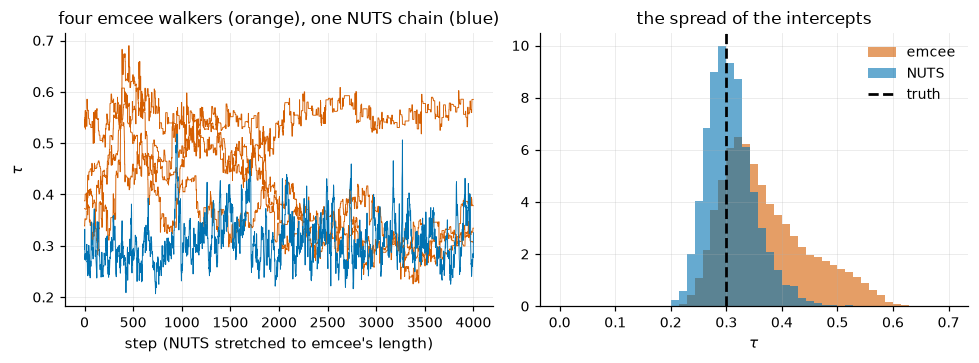

In [6]:
col = hierarchy.columns(tau).item()
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.4))
axes[0].plot(h_emcee[:4, :, col].T, lw=0.6, color=plotstyle.COLOURS[1])
axes[0].plot(
    np.linspace(0, h_emcee.shape[1], h_nuts.shape[1]),
    h_nuts[0, :, col],
    lw=0.6,
    color=plotstyle.COLOURS[0],
)
axes[0].set(
    xlabel="step (NUTS stretched to emcee's length)",
    ylabel=r"$\tau$",
    title="four emcee walkers (orange), one NUTS chain (blue)",
)
bins = np.linspace(0, 0.7, 50)
for chains, colour, name in [(h_emcee, 1, "emcee"), (h_nuts, 0, "NUTS")]:
    axes[1].hist(
        chains[:, :, col].ravel(),
        bins,
        density=True,
        alpha=0.6,
        color=plotstyle.COLOURS[colour],
        label=name,
    )
axes[1].axvline(0.3, ls="--", color="k", label="truth")
axes[1].set(xlabel=r"$\tau$", title="the spread of the intercepts")
axes[1].legend()
plt.tight_layout()
plt.show()

NUTS converges in about half a minute: 395 effective draws, $\hat R$ of
1.009 and no divergences, at about 23 gradient evaluations per draw,
warm-up included.

emcee's 6000 steps of 68 walkers take only 12 s, but $\hat R$ is 1.13, and
the left panel shows why.  The walkers start from prior draws and wander
for thousands of steps without agreeing on $\tau$: the spread *between*
walkers is still larger than the spread *within* each, which is what
$\hat R$ measures, so the pooled histogram is skewed high.  A stretch move
proposes along the line through one other walker; in 33 dimensions most
such proposals are rejected or tiny, so each walker crawls.  emcee's own
warning agrees: its run is shorter than $50\tau$.

The longer run shows that this isn't cured by patience on any reasonable
budget.  emcee's estimate of $\tau$ keeps growing with the run, from 518
steps to 915, because a short run cannot see the slowest motion of the
walkers, and after 76 s $\hat R$ is still 1.04.  NUTS uses the gradient to
move all 33 coordinates together, and had converged in less than half the
time.

## 2. A GP discrepancy: MAP, Laplace and NUTS

The toy of `gp_discrepancy` (recipe 7): a line fitted to data that bend
away from it, with a mean-zero Gaussian-process discrepancy whose amplitude
grows with $x$.  Five parameters: the line's two, and the GP's log length
scale, log amplitude and amplitude slope.

The gradient gives the posterior mode cheaply:
[L-BFGS](https://en.wikipedia.org/wiki/Limited-memory_BFGS) with the exact
gradient, from a few prior draws.  The exact Hessian $H$ at the mode gives
the Laplace approximation, a Gaussian with covariance $-H^{-1}$
(recipe 33).  NUTS then starts its four chains around the mode, and emcee
from the prior.

In [7]:
def truth(x):
    return 0.8 * x + 1.0 + 0.03 * x**2


rng = np.random.default_rng(7)
xg = np.linspace(0.2, 5.0, 30)
toy = rx.Dataset(xg, truth(xg) + rng.normal(0.0, 0.02, xg.size), np.full(xg.size, 0.02))
line = rx.Model(
    lambda x, m, b: m * x + b,
    [
        rx.Parameter("m", prior=stats.norm(0.0, 2.0), latex="m"),
        rx.Parameter("b", prior=stats.norm(0.0, 2.0), latex="b"),
    ],
)
log_A = rx.Parameter("log_A", prior=stats.norm(np.log(0.02), 1.5), latex=r"\log A")
slope = rx.Parameter("amp_slope", prior=stats.norm(1.0, 1.0), latex=r"s_A")
log_ell = rx.Parameter("log_ell", prior=stats.norm(0.5, 1.0), latex=r"\log\ell")
gp = T.kernel(
    lambda le: tinygp.kernels.Matern52(scale=jnp.exp(le)),
    [log_ell],
    amplitude=T.exp_growth_amplitude(5.0),
    amplitude_params=(log_A, slope),
    jitter=1e-6,
)
gp_problem = rx.Problem([rx.Constraint([rx.Comparison(toy, line)], terms=[gp])])
gp_problem.names

['m', 'b', 'log_ell', 'log_A', 'amp_slope']

In [8]:
t0 = time.perf_counter()
fits = [
    minimize(
        lambda t: -gp_problem.log_posterior(t),
        t0_,
        jac=lambda t: -gp_problem.grad_log_posterior(t),
        method="L-BFGS-B",
    )
    for t0_ in gp_problem.sample_prior(8, rng=2)
]
best = min(fits, key=lambda r: r.fun)
laplace_cov = np.linalg.inv(-gp_problem.hessian_log_posterior(best.x))
print(f"MAP and Laplace in {time.perf_counter() - t0:.1f} s")
for name, v, s in zip(gp_problem.names, best.x, np.sqrt(np.diag(laplace_cov))):
    print(f"  {name:10s} {v:7.3f} +/- {s:.3f}")

MAP and Laplace in 3.2 s
  m            0.829 +/- 0.040
  b            0.944 +/- 0.057
  log_ell      1.831 +/- 0.701
  log_A       -3.356 +/- 0.854
  amp_slope    2.391 +/- 0.588


In [9]:
starts = best.x + 0.05 * np.random.default_rng(3).standard_normal((4, gp_problem.ndim))
g_nuts, g_nuts_info = run_nuts(gp_problem, starts, warmup=1000, draws=1000)
g_emcee, g_emcee_info = run_emcee(gp_problem, steps=10000)
score("NUTS", g_nuts, g_nuts_info)
score("emcee", g_emcee, g_emcee_info)

NUTS        22.8 s   142205 evaluations  ESS   401  ESS/s  17.62  R-hat 1.004  27 divergent


emcee       18.1 s   320000 evaluations  not converged, R-hat 1.012  tau 111 steps


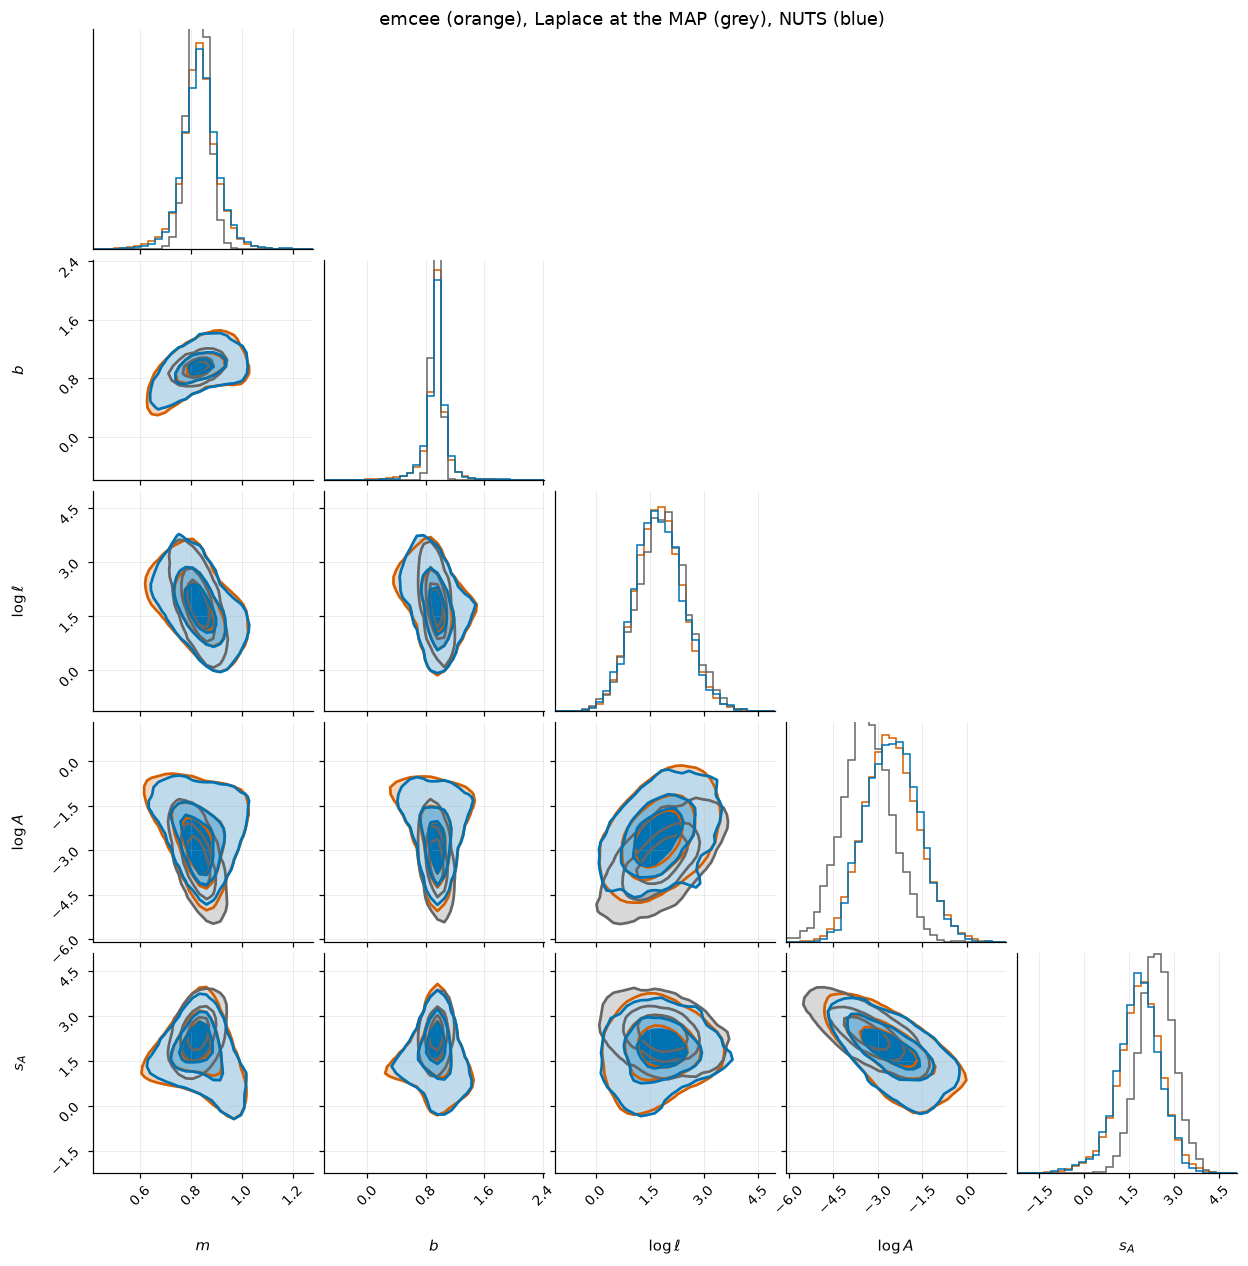

In [10]:
laplace = np.random.default_rng(4).multivariate_normal(best.x, laplace_cov, 4000)
overlay(
    [
        g_emcee.reshape(-1, gp_problem.ndim),
        laplace,
        g_nuts.reshape(-1, gp_problem.ndim),
    ],
    [plotstyle.COLOURS[1], "0.4", plotstyle.COLOURS[0]],
    [f"${p.latex}$" for p in gp_problem.params],
    "emcee (orange), Laplace at the MAP (grey), NUTS (blue)",
)

In [11]:
print("posterior standard deviations")
for k, name in enumerate(gp_problem.names):
    print(
        f"  {name:10s} Laplace {np.sqrt(laplace_cov[k, k]):.3f}   "
        f"NUTS {g_nuts[..., k].std():.3f}   emcee {g_emcee[..., k].std():.3f}"
    )

posterior standard deviations
  m          Laplace 0.040   NUTS 0.071   emcee 0.073
  b          Laplace 0.057   NUTS 0.174   emcee 0.189
  log_ell    Laplace 0.701   NUTS 0.676   emcee 0.667
  log_A      Laplace 0.854   NUTS 0.873   emcee 0.913
  amp_slope  Laplace 0.588   NUTS 0.727   emcee 0.747


The MAP and the Laplace approximation take 3 s together.  Started around
the MAP, NUTS gives 401 effective draws in 23 s, with $\hat R$ of 1.004.
Its 27 divergences out of 4000 draws are a warning, not a failure:
trajectories that met sharp curvature (where a small amplitude leaves the
length scale unconstrained) and were stopped.  Many divergences would mean
the posterior is not being explored.

emcee is cheap in five dimensions.  Its 10 000 steps take 18 s, and its
$\tau$ of 111 steps is short enough that the kept 6667 steps meet emcee's
own $50\tau$ rule.  Even so, $\hat R$ is 1.012, just above the threshold:
the walkers still disagree slightly in the tail of the amplitude
parameters, and a somewhat longer run would pass.  On a problem this small
the two samplers are comparable, and the posteriors agree.

The Laplace approximation gets the hyperparameters' widths about right
($\log\ell$ 0.70 against 0.68 from NUTS), but not the line's: $m$ comes out
0.040 against 0.071 and $b$ 0.057 against 0.174.  At the mode it holds the
amplitude at its best value, while the posterior averages over amplitudes,
and a larger amplitude lets the line move further.  Its $\log A$ is also
centred at the mode of a skewed marginal, below the posterior's bulk.
Laplace is a quick check of where the posterior is, not a substitute for
sampling it.

## 3. The p + ⁴⁰Ca optical model

The log-space model of `local_optical_model_calibration`: seven potential
parameters, each bounded below, and the inferred point-to-point and common
relative errors $s$ and $b$, each with a log-uniform prior (recipes 10, 19).
That notebook calibrates it with dynesty, which also gives the evidence.

An optical-model posterior has local modes: a deeper, narrower well can
mimic a shallower, wider one.  NUTS explores the mode it starts in, so we
first find the best one with the gradient, L-BFGS on the unconstrained
density from eight prior draws, and start the chains around it.  Started
from four prior draws instead, the chains settle in different modes and
never agree: $\hat R$ stays far above 1.  The forward model makes each
gradient cost about four likelihood evaluations, so NUTS runs two chains
here, and dynesty runs alongside with 100 live points.

In [12]:
df = pd.read_csv("data/p40ca_elastic_35mev.csv")
measurement = {
    "x": df["angle_cm_deg"].to_numpy(),
    "y": df["ratio_to_rutherford"].to_numpy(),
    "statistical_err": df["stat_err"].to_numpy(),
    "Einc": 35.0,
    "quantity": "dXS/dRuth",
    "y_units": "no-dim",
    "x_units": "CM-degrees",
    "systematic_norm_err": 0.0,
    "systematic_offset_err": 0.0,
    "subentry": "O1199007",
}
reaction = jitr.reactions.ElasticReaction(target=(40, 20), projectile=(1, 1))
data = rx.from_measurement(measurement, reaction=reaction)

A13 = 40 ** (1 / 3)
mso = 1.0 / jitr.utils.constants.WAVENUMBER_PION


def central(r, Vv, Wv, Rv, av, Wd, Rd, ad):
    return -(Vv + 1j * Wv) * woods_saxon_safe(r, Rv, av) - 1j * Wd * (
        -4 * ad
    ) * woods_saxon_prime_safe(r, Rd, ad)


def spin_orbit(r, Vso, Rso, aso):
    return Vso * mso**2 * thomas_safe(r, Rso, aso)


def coulomb(r):
    return coulomb_charged_sphere(
        r, reaction.target.Z * reaction.projectile.Z, 1.3 * A13
    )


names = ["Vv", "Wv", "Rv", "av", "Wd", "Rd", "ad"]
start = np.array([45.0, 3.0, 1.18 * A13, 0.68, 6.0, 1.28 * A13, 0.55])
prior_sd = np.array([8.0, 3.0, 0.25, 0.15, 5.0, 0.25, 0.15])
lower = np.array([0.0, 0.0, 1.0, 0.2, 0.0, 1.0, 0.2])
params = [
    rx.Parameter(n, prior=stats.norm(mu_, sd), bounds=(lo, np.inf))
    for n, mu_, sd, lo in zip(names, start, prior_sd, lower)
]
omp = rx.reactions.ElasticXS(
    "dXS/dRuth",
    central,
    spin_orbit,
    lambda ws, *x: (tuple(x), (5.5, 1.0 * A13, 0.6)),
    params,
    coulomb=coulomb,
    lmax=30,
)


def log_uniform(lo, hi):
    return stats.uniform(np.log(lo), np.log(hi) - np.log(lo))


log_s = rx.Parameter("log_s", prior=log_uniform(0.05, 2.0))
log_b = rx.Parameter("log_b", prior=log_uniform(0.05, 2.0))


def point_to_point_sd(c, log_s, log_b):
    s2, b2 = jnp.exp(2 * log_s), jnp.exp(2 * log_b)
    return jnp.full(len(c), jnp.sqrt(jnp.log1p(s2 / (1 + b2))))


def common_sd(c, log_b):
    return jnp.full(len(c), jnp.sqrt(jnp.log1p(jnp.exp(2 * log_b))))


errors = [
    rx.Term(point_to_point_sd, (log_s, log_b), kind="diag"),
    rx.Term(common_sd, (log_b,), kind="mode"),
]
omp_problem = rx.Problem(
    [rx.Constraint([rx.Comparison(data, omp, space=tf.log)], terms=errors)]
)
omp_problem.names

['Vv', 'Wv', 'Rv', 'av', 'Wd', 'Rd', 'ad', 'log_s', 'log_b']

In [13]:
grad_u = jax.jit(jax.grad(omp_problem.log_posterior_unconstrained))
t0 = time.perf_counter()
fits = [
    minimize(
        lambda z: -omp_problem.log_posterior_unconstrained(z),
        omp_problem.to_unconstrained(theta),
        jac=lambda z: -np.asarray(grad_u(z)),
        method="L-BFGS-B",
    )
    for theta in omp_problem.sample_prior(8, rng=1)
]
print(f"8 searches in {time.perf_counter() - t0:.1f} s; log posterior at each end:")
print(np.round(sorted(-f.fun for f in fits), 1))
z_map = min(fits, key=lambda f: f.fun).x
jitter = 0.05 * np.random.default_rng(5).standard_normal((2, omp_problem.ndim))
starts = np.array([omp_problem.to_theta(z_map + dz) for dz in jitter])
o_nuts, o_nuts_info = run_nuts(omp_problem, starts, warmup=300, draws=1000)
o_dyn, o_dyn_info = run_dynesty(omp_problem, nlive=100)
score("NUTS", o_nuts, o_nuts_info)
score("dynesty", o_dyn, o_dyn_info)

8 searches in 12.3 s; log posterior at each end:
[-54.8 -53.4 -24.  -24.  -21.4 -21.4 -12.8 -12.8]


NUTS       866.8 s   108892 evaluations  ESS   423  ESS/s   0.49  R-hat 1.004  0 divergent
dynesty     85.6 s    42656 evaluations  ESS   547  ESS/s   6.39


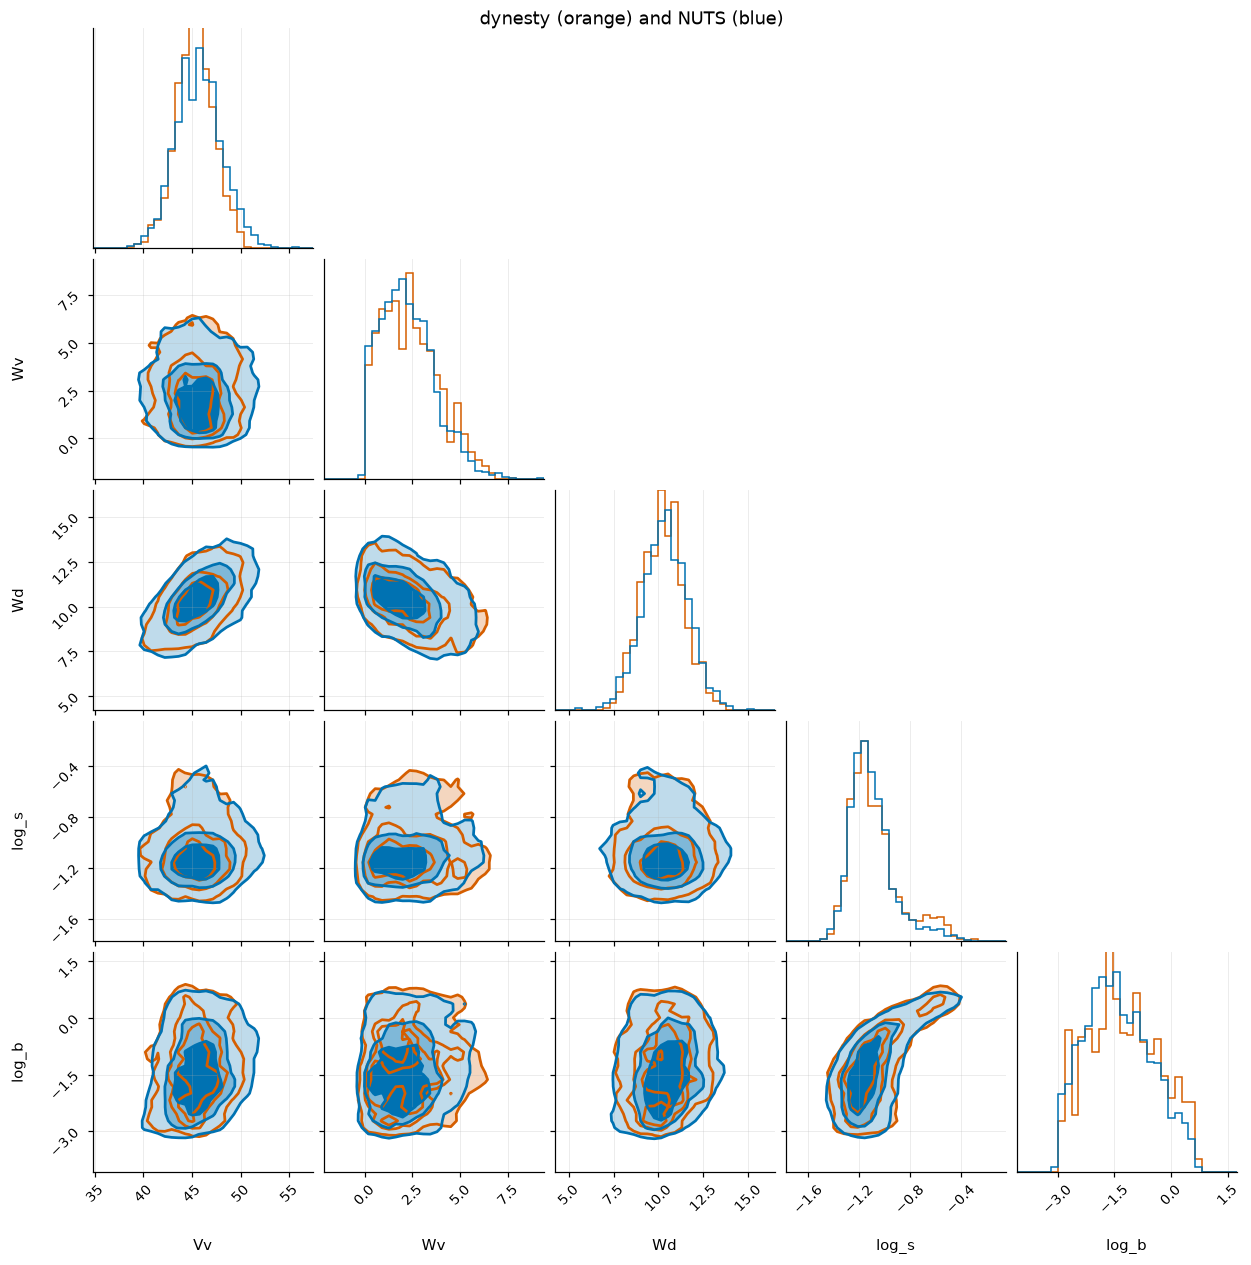

In [14]:
shown = ["Vv", "Wv", "Wd", "log_s", "log_b"]
cols = omp_problem.columns([p for p in omp_problem.params if p.name in shown])
overlay(
    [o_dyn[0][:, cols], o_nuts.reshape(-1, omp_problem.ndim)[:, cols]],
    [plotstyle.COLOURS[1], plotstyle.COLOURS[0]],
    shown,
    "dynesty (orange) and NUTS (blue)",
)

The eight searches end at four different log posteriors, from −54.8 to
−12.8: these are the local modes, and NUTS starts from the best one.

Both samplers converge to the same posterior.  NUTS gives 423 effective
draws with $\hat R$ of 1.004 and no divergences, but takes 867 s; dynesty
gives 547 in 86 s, plus the evidence.  Here dynesty is more than ten times
cheaper per effective draw, for two reasons:
- each gradient through the R-matrix solve costs about four likelihood
  evaluations;
- the posterior is correlated (the depths $V_v$ and $W_d$ trade off against
  each other), so the trajectories are long, about 40 gradient evaluations
  per draw.

In nine dimensions, nested sampling's shrinking of the prior volume is
still efficient.  So for a reaction model like this one dynesty stays the
default, and NUTS is a check on the posterior, or the tool for when a model
grows many more parameters.

## Takeaways

- **Choose the sampler by the problem.**  With many parameters and a smooth,
  single-mode posterior, NUTS wins outright: the 33-parameter hierarchy
  converged in about 30 s, while emcee had not converged after 76 s.  With a
  handful of parameters, emcee and dynesty are cheap and as good.  With
  local modes, or when the evidence is wanted, use dynesty; NUTS started
  from the MAP then confirms its posterior.
- **Gradient samplers need the unconstrained density.**
  `log_posterior_unconstrained` and `to_theta` handle every bound,
  including those implied by a prior (recipe 41).
- **Read the diagnostics before the ESS.**  An ESS means something only
  when $\hat R$ is below about 1.01.  For emcee, also check that the run is
  longer than $50\tau$, and remember that an estimate of $\tau$ from a run
  that is too short is itself too short.
- **The Laplace approximation is a quick check.**  The exact Hessian makes
  it nearly free, but it misses the width that averaging over
  hyperparameters adds.

The benchmark behind these numbers, on more problems and longer budgets,
is `benchmarks/bench_samplers.py`; its table is in the design document's
performance section.